# Decision trees

A decision tree makes a prediction by asking a series of **yes/no questions** about the data, like a flowchart:

```
Is it raining?
├── yes → stay inside
└── no  → Is it colder than 10°C?
          ├── yes → stay inside
          └── no  → play outside
```

The tree learns which questions to ask, and in which order, from examples.

In this notebook we:

1. Train a tree on a tiny made-up example and draw it.
2. See how the tree picks its questions.
3. Train trees on a real dataset.
4. See what happens when a tree asks too many questions.
5. Read the questions the final tree asks.

## 1. A tiny example

Twelve days, each described by the temperature, whether it rained, and the wind speed, with the answer we want to predict: did we play outside (1) or not (0)?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

days = pd.DataFrame({
    "temperature": [25, 18, 8, 30, 12, 5, 22, 15, 28, 9, 20, 16],
    "raining":     [0,  0,  0, 1,  0,  1, 0,  1,  0,  0, 1,  0],
    "wind_speed":  [10, 5,  20, 15, 30, 10, 5, 5,  25, 15, 10, 8],
    "played":      [1,  1,  0, 0,  0,  0, 1,  0,  1,  0, 0,  1],
})
days

,temperature,raining,wind_speed,played
0,25,0,10,1
1,18,0,5,1
2,8,0,20,0
3,30,1,15,0
4,12,0,30,0
5,5,1,10,0
6,22,0,5,1
7,15,1,5,0
8,28,0,25,1
9,9,0,15,0


We give the tree the three columns as inputs (`X`) and the answer column (`y`), and let it learn. `max_depth=2` means it may ask at most two questions in a row.

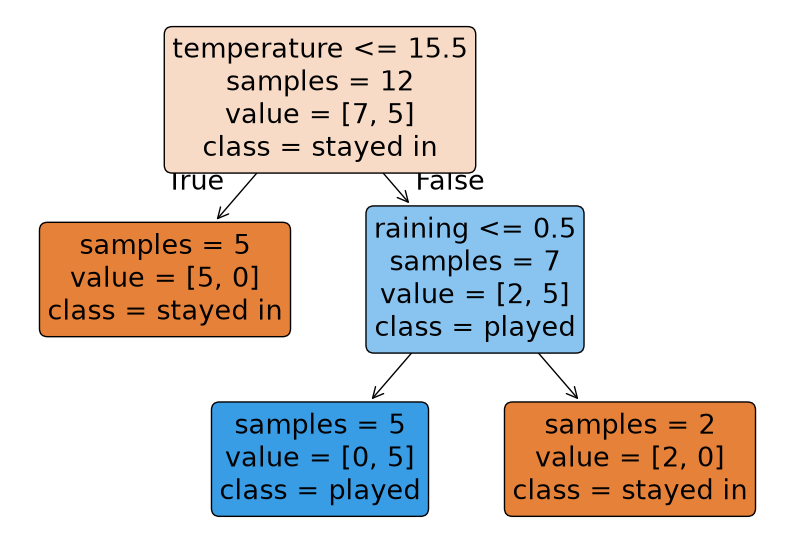

In [2]:
X = days[["temperature", "raining", "wind_speed"]]
y = days["played"]

tiny_tree = DecisionTreeClassifier(max_depth=2, random_state=0)
tiny_tree.fit(X, y)

plt.figure(figsize=(10, 7))
plot_tree(tiny_tree, feature_names=list(X.columns), class_names=["stayed in", "played"],
          filled=True, impurity=False, rounded=True)
plt.show()

### How to read the drawing

Each box is a point in the flowchart:

- **The first line** is the question, for example `raining <= 0.5` (is `raining` 0, i.e. no rain?). If the answer is **yes, go left** (the arrow marked `True`); if **no, go right** (`False`).
- **samples** is how many of the training days reached this box.
- **value** is how many of them had each answer: `[stayed in, played]`.
- **class** is the tree's prediction for days that end up here: whichever answer is more common in the box.
- **Colour** shows which answer is winning, and how strongly (darker = more one-sided).

The boxes at the bottom with no question are the **leaves**: that's where a prediction is made.

The same tree as plain text:

In [3]:
print(export_text(tiny_tree, feature_names=list(X.columns), class_names=["stayed in", "played"]))

|--- temperature <= 15.50
|   |--- class: stayed in
|--- temperature >  15.50
|   |--- raining <= 0.50
|   |   |--- class: played
|   |--- raining >  0.50
|   |   |--- class: stayed in



## 2. How does the tree pick its questions?

At every box, the tree tries **every column** and **every place it could cut** that column (for example temperature ≤ 10, ≤ 11, ≤ 12, …). For each possible question it checks how well the yes-group and no-group are separated.

It picks the question that leaves the two groups **least mixed**: ideally one side is all "played" and the other all "stayed in". Then it repeats the same thing inside each side, until it reaches `max_depth` or a box contains only one kind of answer.

So the questions near the top of the tree are the ones that split the data best.

## 3. A real dataset

This works with any table where each row is one example and the answer has two possible values. Change the settings to use your own data. By default it uses a dataset built into scikit-learn: measurements of breast tissue samples, labelled cancerous (`malignant`) or not (`benign`).

If your data has many rows per person (like one row per key press), turn it into one row per person first, as in the feature-picking notebook.

In [4]:
# ---- settings: change these for your own data ----
DATA_FILE = None          # path to a .csv or .parquet file. None uses scikit-learn's built-in example data
TARGET = "diagnosis"      # the column we want to predict. It must have exactly two different values
POSITIVE = "malignant"    # which of the two values counts as 1 ("yes")
FEATURES = None           # list of columns to use as inputs. None uses every number column

In [5]:
from sklearn.model_selection import train_test_split

if DATA_FILE is None:
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer(as_frame=True).frame.rename(columns={"target": TARGET})
    data[TARGET] = data[TARGET].map({0: "malignant", 1: "benign"})
elif str(DATA_FILE).endswith(".parquet"):
    data = pd.read_parquet(DATA_FILE)
else:
    data = pd.read_csv(DATA_FILE)

data = data.dropna(subset=[TARGET])
data[TARGET] = (data[TARGET] == POSITIVE).astype(int)   # 1 = POSITIVE, 0 = the other answer

if FEATURES is None:
    FEATURES = [c for c in data.select_dtypes("number").columns if c != TARGET]
data = data.dropna(subset=FEATURES)

# training group: to learn. practice group: to make choices. test group: the final score, used once.
rest, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=42)
train, practice = train_test_split(rest, test_size=0.25, stratify=rest[TARGET], random_state=42)

print(len(data), "rows,", len(FEATURES), "features")
print(len(train), "training,", len(practice), "practice,", len(test), "test")

569 rows, 30 features
341 training, 114 practice, 114 test


## 4. How many questions should the tree ask?

A deeper tree asks more questions, so it can split the training data into smaller and smaller groups. Eventually every leaf holds just a few rows and the tree gets the training data **perfectly** right. But by then it is memorising the training rows (including their quirks and mistakes) rather than learning patterns that hold for new data.

To see this, we train trees of depth 1 to 12 and score each one with ROC AUC on:

- the **training** group (data it learned from), and
- the **practice** group (data it hasn't seen).

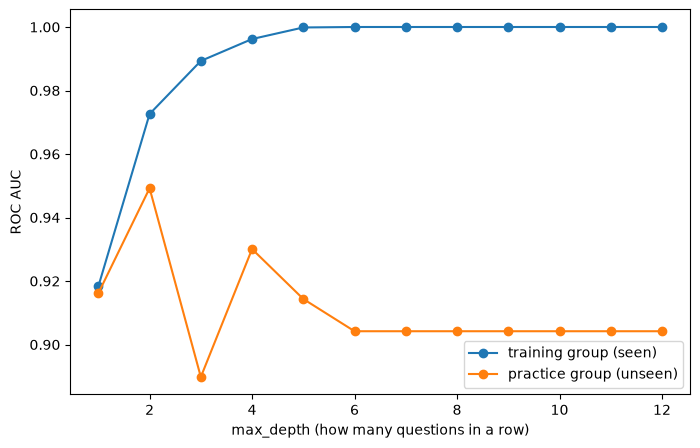

,depth,training,practice
0,1,0.918,0.916
1,2,0.973,0.949
2,3,0.989,0.890
3,4,0.996,0.930
4,5,1.000,0.914
5,6,1.000,0.904
6,7,1.000,0.904
7,8,1.000,0.904
8,9,1.000,0.904
9,10,1.000,0.904


In [6]:
from sklearn.metrics import roc_auc_score

def auc(tree, group):
    return roc_auc_score(group[TARGET], tree.predict_proba(group[FEATURES])[:, 1])

depths = range(1, 13)
scores = []
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(train[FEATURES], train[TARGET])
    scores.append({"depth": depth, "training": auc(tree, train), "practice": auc(tree, practice)})
scores = pd.DataFrame(scores)

plt.figure(figsize=(8, 5))
plt.plot(scores["depth"], scores["training"], marker="o", label="training group (seen)")
plt.plot(scores["depth"], scores["practice"], marker="o", label="practice group (unseen)")
plt.xlabel("max_depth (how many questions in a row)")
plt.ylabel("ROC AUC")
plt.legend()
plt.show()

scores.round(3)

**How to read it:** the training score keeps climbing towards 1.0 as the tree gets deeper. The practice score rises at first, then stops improving or drops. The gap between the two lines is the tree memorising the training data.

This is called **overfitting**. We pick the depth with the best practice score: the point where the tree has learned real patterns but hasn't started memorising.

In [7]:
best_depth = int(scores.loc[scores["practice"].idxmax(), "depth"])
print("best depth on the practice group:", best_depth)

best depth on the practice group: 2


## 5. The final tree

We train a tree with the chosen depth on the training and practice groups together, then score it **once** on the test group.

test ROC AUC: 0.919


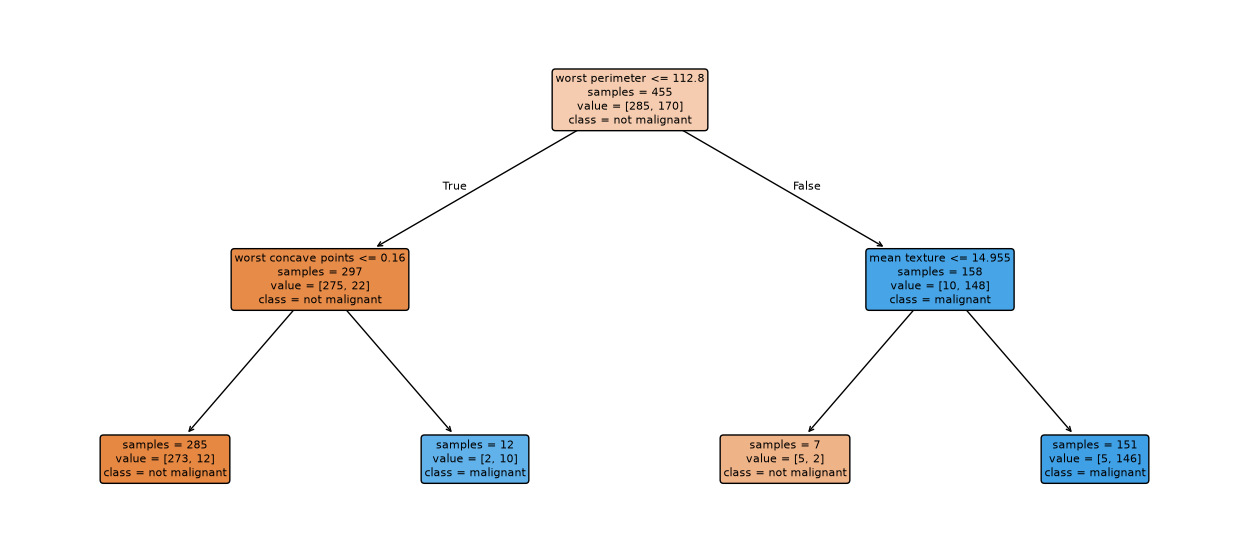

In [8]:
learn = pd.concat([train, practice])
final_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(learn[FEATURES], learn[TARGET])
print("test ROC AUC:", round(auc(final_tree, test), 3))

class_names = [f"not {POSITIVE}", str(POSITIVE)]
plt.figure(figsize=(min(4 * 2 ** best_depth, 30), 2.5 * best_depth + 2))
plot_tree(final_tree, feature_names=FEATURES, class_names=class_names,
          filled=True, impurity=False, rounded=True, fontsize=8)
plt.show()

### Which features did the tree use?

A tree only uses the features that made good questions. **Feature importance** measures how much each feature's questions helped separate the two answers, as a share of the total (they add up to 1). Features the tree never asked about get 0.

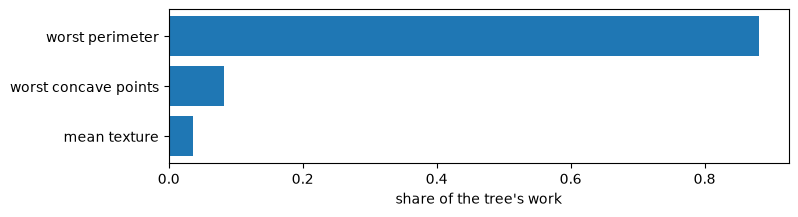

3 of 30 features were used


In [9]:
importance = pd.Series(final_tree.feature_importances_, index=FEATURES)
importance = importance[importance > 0].sort_values()

plt.figure(figsize=(8, max(2, 0.4 * len(importance))))
plt.barh(importance.index, importance.values)
plt.xlabel("share of the tree's work")
plt.show()

print(len(importance), "of", len(FEATURES), "features were used")

### Following one prediction

Here is the path one test example takes through the tree, question by question, and the prediction it ends with.

In [10]:
example = test[FEATURES].iloc[[0]]
tree_ = final_tree.tree_
node = 0
while tree_.children_left[node] != -1:   # -1 means this box is a leaf
    feature = FEATURES[tree_.feature[node]]
    cut = tree_.threshold[node]
    value = example[feature].iloc[0]
    answer = value <= cut
    print(f"Is {feature} <= {cut:.3f}?  It is {value:.3f}, so {'yes, go left' if answer else 'no, go right'}")
    node = tree_.children_left[node] if answer else tree_.children_right[node]

probability = final_tree.predict_proba(example)[0, 1]
print(f"\nPrediction: {probability:.0%} chance of {POSITIVE}")
print("Real answer:", POSITIVE if test[TARGET].iloc[0] == 1 else f"not {POSITIVE}")

Is worst perimeter <= 112.800?  It is 83.740, so yes, go left
Is worst concave points <= 0.160?  It is 0.090, so yes, go left

Prediction: 4% chance of malignant
Real answer: not malignant


## Summary

- A decision tree predicts by asking yes/no questions, one after another.
- At each step it picks the question that best separates the two answers.
- Deeper trees fit the training data better, but too deep and they memorise it (**overfitting**). We choose the depth using data the tree hasn't seen.
- Trees are easy to read: you can follow every prediction question by question, and see which features they used.